# Phase 1 - Convolutional Neural Networks

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.

## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [5]:
# Run to import necessary libraries
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import time


# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [6]:
train_data = datasets.MNIST(root = './data', train = True,
                            transform = transforms.ToTensor(), download = True)

test_data = datasets.MNIST(root = './data', train = False,
                           transform = transforms.ToTensor())

batch_size = 32

train_loader = torch.utils.data.DataLoader(dataset = train_data,
                                           batch_size = batch_size,
                                           shuffle = True)

test_loader = torch.utils.data.DataLoader(dataset = test_data,
                                          batch_size = batch_size,
                                          shuffle = False)


In [7]:
# Function should input the dataloader, and show random 10 images and their labels as title to plot
def show_imgs():
    ''' TODO '''

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [8]:
def test_accuracy(model, test_loader, input_size, device):
    model.to(device)
    correct = 0
    total = 0
    with torch.no_grad():
        for test_data in test_loader:
            images, labels = test_data[0].to(device), test_data[1].to(device)
            images = images.view(-1, input_size)
            outputs = net(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    print('Accuracy: %d %%' % (100 * correct / total))


## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [9]:
def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device):
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(num_epochs):
        # ---------- Train ----------
        start = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            images = images.view(images.size(0), -1)   # flatten to (batch, 784), same as test_accuracy

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100 * correct / total
        train_time = time.time() - start

        # ---------- Test ----------
        start = time.time()
        model.eval()
        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                images = images.view(images.size(0), -1)

                outputs = model(images)
                loss = loss_fn(outputs, labels)

                running_loss += loss.item() * labels.size(0)
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        test_loss = running_loss / total
        test_acc = 100 * correct / total
        test_time = time.time() - start

        # ---------- Save + print ----------
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f'Epoch [{epoch+1}/{num_epochs}]  '
              f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.2f}%  ({train_time:.1f}s)  |  '
              f'Test Loss: {test_loss:.4f}  Test Acc: {test_acc:.2f}%  ({test_time:.1f}s)')

    return history


## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [10]:
def plot_learning_curve(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    ax1.plot(epochs, history['train_loss'], marker='o', label='Train')
    ax1.plot(epochs, history['test_loss'], marker='o', label='Test')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Loss')
    ax1.legend()
    ax1.grid(True)

    # Accuracy
    ax2.plot(epochs, history['train_acc'], marker='o', label='Train')
    ax2.plot(epochs, history['test_acc'], marker='o', label='Test')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.set_title('Accuracy')
    ax2.legend()
    ax2.grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [11]:
class Net(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net,self).__init__()
        self.fc1 = nn.Linear(input_size, 500)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(500, num_classes)

    def forward(self,x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [12]:
class Net2(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net2, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=20, kernel_size=3, stride=1)  # 1x28x28 -> 20x26x26
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes)                                  # 13520 -> 10

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.conv1(x)
        out = self.relu(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        return out


# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

Epoch [1/10]  Train Loss: 0.2472  Train Acc: 92.79%  (10.1s)  |  Test Loss: 0.1935  Test Acc: 94.58%  (1.1s)
Epoch [2/10]  Train Loss: 0.1654  Train Acc: 95.61%  (10.2s)  |  Test Loss: 0.1416  Test Acc: 96.07%  (1.1s)
Epoch [3/10]  Train Loss: 0.1460  Train Acc: 96.27%  (10.3s)  |  Test Loss: 0.1469  Test Acc: 96.26%  (1.1s)
Epoch [4/10]  Train Loss: 0.1403  Train Acc: 96.58%  (9.6s)  |  Test Loss: 0.1668  Test Acc: 96.31%  (1.1s)
Epoch [5/10]  Train Loss: 0.1232  Train Acc: 96.93%  (9.5s)  |  Test Loss: 0.1690  Test Acc: 96.45%  (1.1s)
Epoch [6/10]  Train Loss: 0.1197  Train Acc: 97.04%  (12.3s)  |  Test Loss: 0.1883  Test Acc: 96.35%  (1.6s)
Epoch [7/10]  Train Loss: 0.1225  Train Acc: 97.22%  (11.0s)  |  Test Loss: 0.1937  Test Acc: 96.71%  (1.1s)
Epoch [8/10]  Train Loss: 0.1090  Train Acc: 97.45%  (9.6s)  |  Test Loss: 0.2109  Test Acc: 96.17%  (1.1s)
Epoch [9/10]  Train Loss: 0.1057  Train Acc: 97.56%  (9.8s)  |  Test Loss: 0.2289  Test Acc: 96.34%  (1.1s)
Epoch [10/10]  Train Lo

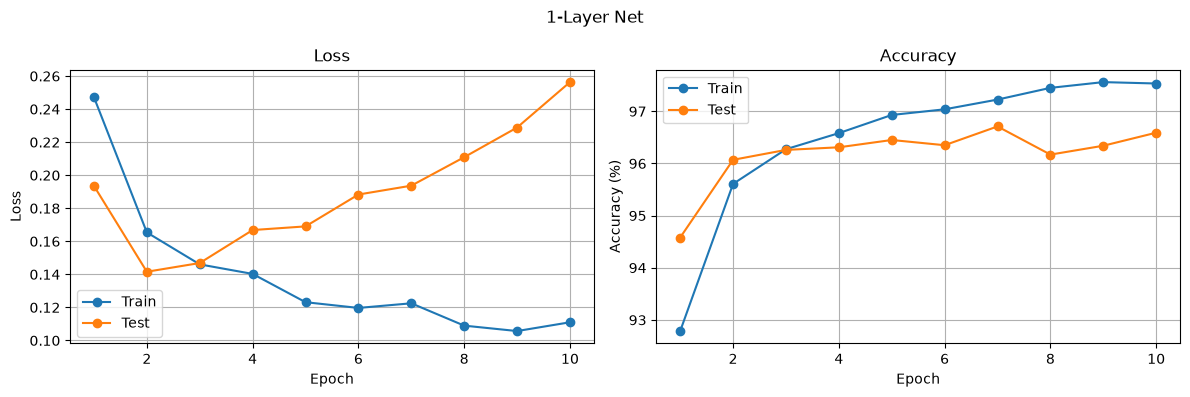

Accuracy: 96 %


In [13]:
# Define Parameters
input_size = 784      # 28 * 28 pixels per image
num_classes = 10      # digits 0-9
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
history = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history, '1-Layer Net')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

Epoch [1/10]  Train Loss: 0.2078  Train Acc: 95.07%  (12.3s)  |  Test Loss: 0.1032  Test Acc: 96.78%  (1.5s)
Epoch [2/10]  Train Loss: 0.0739  Train Acc: 97.74%  (12.0s)  |  Test Loss: 0.0775  Test Acc: 97.73%  (1.3s)
Epoch [3/10]  Train Loss: 0.0532  Train Acc: 98.33%  (12.6s)  |  Test Loss: 0.0953  Test Acc: 97.43%  (1.2s)
Epoch [4/10]  Train Loss: 0.0403  Train Acc: 98.73%  (11.9s)  |  Test Loss: 0.1134  Test Acc: 97.40%  (1.2s)
Epoch [5/10]  Train Loss: 0.0311  Train Acc: 99.03%  (11.9s)  |  Test Loss: 0.1146  Test Acc: 97.53%  (1.3s)
Epoch [6/10]  Train Loss: 0.0238  Train Acc: 99.23%  (12.0s)  |  Test Loss: 0.1356  Test Acc: 97.62%  (1.3s)
Epoch [7/10]  Train Loss: 0.0235  Train Acc: 99.27%  (12.0s)  |  Test Loss: 0.1586  Test Acc: 97.50%  (1.3s)
Epoch [8/10]  Train Loss: 0.0216  Train Acc: 99.38%  (12.2s)  |  Test Loss: 0.1710  Test Acc: 97.43%  (1.3s)
Epoch [9/10]  Train Loss: 0.0170  Train Acc: 99.53%  (12.1s)  |  Test Loss: 0.2029  Test Acc: 97.77%  (1.3s)
Epoch [10/10]  Trai

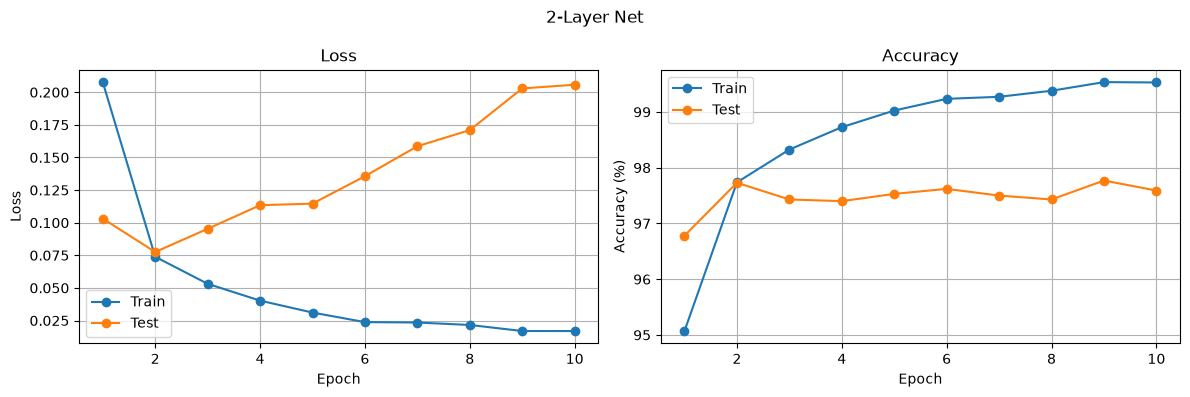

Accuracy: 97 %


In [14]:
# Define Parameters
input_size = 784
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
history = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history, '2-Layer Net')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)


A learning curve plots a model's performance against training time (epochs here). The curves in Section 4 show loss and accuracy for both the training set and t he test set after each epoch. They're useful because they show how training is going, not just the final number

---

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

Epoch [1/10]  Train Loss: 0.1651  Train Acc: 95.13%  (12.6s)  |  Test Loss: 0.0704  Test Acc: 97.82%  (1.3s)
Epoch [2/10]  Train Loss: 0.0629  Train Acc: 98.11%  (12.3s)  |  Test Loss: 0.0646  Test Acc: 97.88%  (1.3s)
Epoch [3/10]  Train Loss: 0.0432  Train Acc: 98.65%  (12.0s)  |  Test Loss: 0.0630  Test Acc: 97.97%  (1.3s)
Epoch [4/10]  Train Loss: 0.0313  Train Acc: 98.98%  (12.0s)  |  Test Loss: 0.0681  Test Acc: 98.12%  (1.3s)
Epoch [5/10]  Train Loss: 0.0210  Train Acc: 99.31%  (12.1s)  |  Test Loss: 0.0754  Test Acc: 97.84%  (1.3s)
Epoch [6/10]  Train Loss: 0.0150  Train Acc: 99.50%  (11.8s)  |  Test Loss: 0.0773  Test Acc: 98.01%  (1.3s)
Epoch [7/10]  Train Loss: 0.0117  Train Acc: 99.58%  (11.9s)  |  Test Loss: 0.0981  Test Acc: 97.65%  (1.3s)
Epoch [8/10]  Train Loss: 0.0076  Train Acc: 99.76%  (12.7s)  |  Test Loss: 0.0887  Test Acc: 97.92%  (1.4s)
Epoch [9/10]  Train Loss: 0.0062  Train Acc: 99.80%  (12.8s)  |  Test Loss: 0.0908  Test Acc: 97.95%  (1.3s)
Epoch [10/10]  Trai

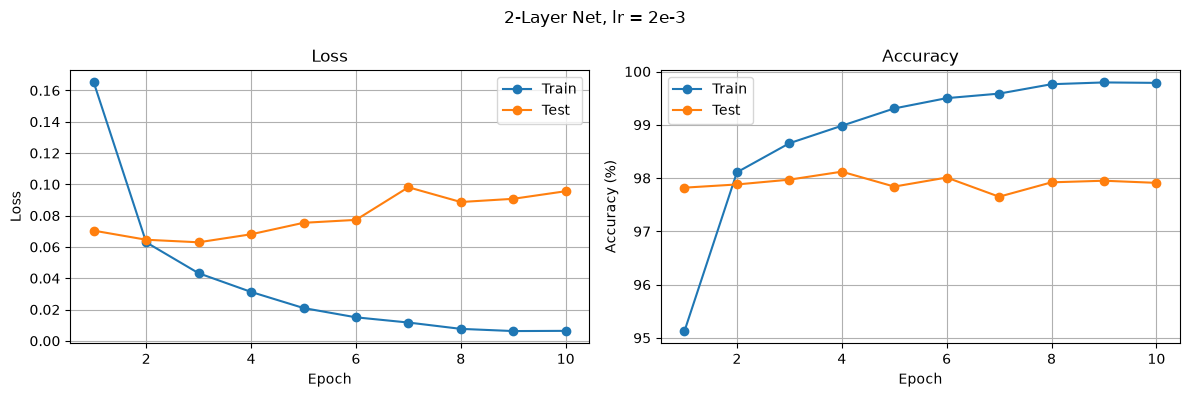

Accuracy: 97 %


In [15]:
# 2e-3

input_size = 784
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_2e3 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_2e3, '2-Layer Net, lr = 2e-3')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.3507  Train Acc: 90.13%  (12.2s)  |  Test Loss: 0.2294  Test Acc: 93.54%  (1.2s)
Epoch [2/10]  Train Loss: 0.1882  Train Acc: 94.75%  (11.9s)  |  Test Loss: 0.1349  Test Acc: 96.44%  (1.3s)
Epoch [3/10]  Train Loss: 0.1136  Train Acc: 96.86%  (11.8s)  |  Test Loss: 0.0965  Test Acc: 97.25%  (1.3s)
Epoch [4/10]  Train Loss: 0.0811  Train Acc: 97.76%  (11.7s)  |  Test Loss: 0.0762  Test Acc: 97.78%  (1.3s)
Epoch [5/10]  Train Loss: 0.0639  Train Acc: 98.27%  (11.9s)  |  Test Loss: 0.0766  Test Acc: 97.52%  (1.3s)
Epoch [6/10]  Train Loss: 0.0524  Train Acc: 98.55%  (11.8s)  |  Test Loss: 0.0638  Test Acc: 98.04%  (1.2s)
Epoch [7/10]  Train Loss: 0.0444  Train Acc: 98.75%  (11.9s)  |  Test Loss: 0.0599  Test Acc: 98.08%  (1.3s)
Epoch [8/10]  Train Loss: 0.0379  Train Acc: 98.96%  (11.9s)  |  Test Loss: 0.0561  Test Acc: 98.23%  (1.3s)
Epoch [9/10]  Train Loss: 0.0329  Train Acc: 99.11%  (11.9s)  |  Test Loss: 0.0603  Test Acc: 98.01%  (1.3s)
Epoch [10/10]  Trai

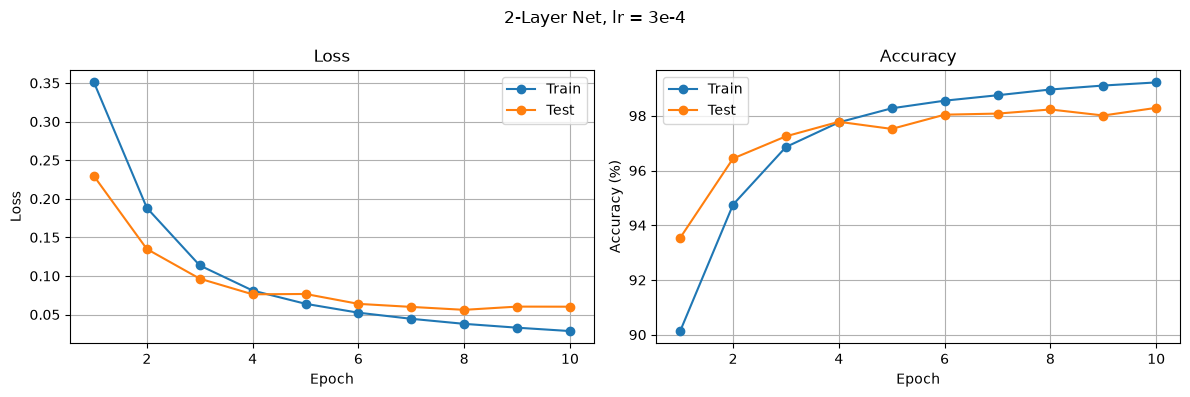

Accuracy: 98 %


In [16]:
# 3e-4
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_3e4 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_3e4, '2-Layer Net, lr = 3e-4')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.3785  Train Acc: 91.84%  (12.3s)  |  Test Loss: 0.2530  Test Acc: 92.73%  (1.3s)
Epoch [2/10]  Train Loss: 0.2668  Train Acc: 93.45%  (12.0s)  |  Test Loss: 0.3031  Test Acc: 91.46%  (1.3s)
Epoch [3/10]  Train Loss: 0.2547  Train Acc: 94.09%  (11.8s)  |  Test Loss: 0.3858  Test Acc: 90.03%  (1.3s)
Epoch [4/10]  Train Loss: 0.2354  Train Acc: 94.27%  (12.0s)  |  Test Loss: 0.2861  Test Acc: 93.36%  (1.3s)
Epoch [5/10]  Train Loss: 0.2214  Train Acc: 94.82%  (11.8s)  |  Test Loss: 0.3916  Test Acc: 93.66%  (1.3s)
Epoch [6/10]  Train Loss: 0.2206  Train Acc: 95.01%  (11.9s)  |  Test Loss: 0.3597  Test Acc: 92.21%  (1.3s)
Epoch [7/10]  Train Loss: 0.2142  Train Acc: 95.15%  (12.0s)  |  Test Loss: 0.4144  Test Acc: 91.86%  (1.3s)
Epoch [8/10]  Train Loss: 0.2119  Train Acc: 95.28%  (11.8s)  |  Test Loss: 0.5082  Test Acc: 90.70%  (1.3s)
Epoch [9/10]  Train Loss: 0.3341  Train Acc: 92.38%  (11.8s)  |  Test Loss: 0.3785  Test Acc: 89.96%  (1.3s)
Epoch [10/10]  Trai

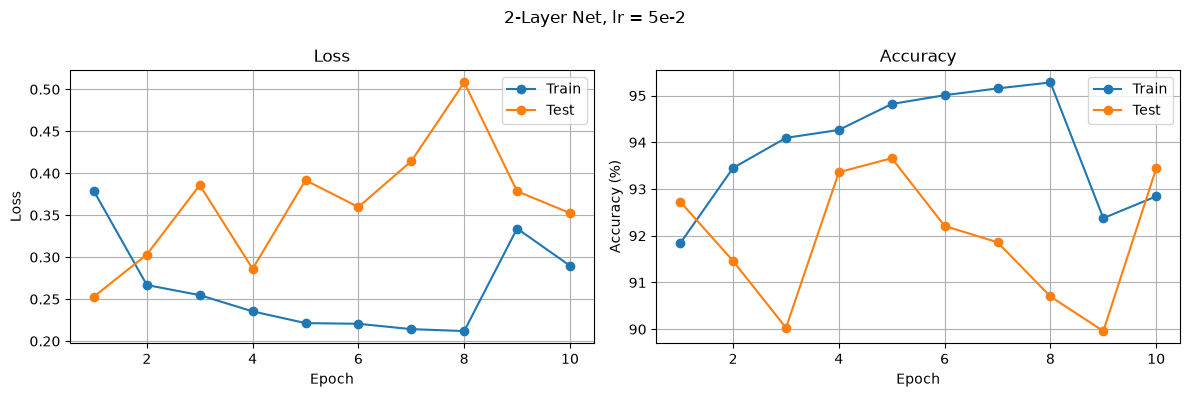

Accuracy: 93 %


In [17]:
# 5e-2
input_size = 784
num_classes = 10
lr = 5e-2
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_5e2 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_5e2, '2-Layer Net, lr = 5e-2')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

lr = 2e-3 — Overfitting. Training loss kept dropping to almost zero (0.006), but test loss was lowest at epoch 3 (0.063) and then went back up to 0.096. The model started memorizing the training data instead of generalizing.

lr = 3e-4 — Training well. Train and test loss both went down steadily and stayed close together. It learned slower at first but got the best test accuracy (98.29%).

lr = 5e-2 — Underfitting / unstable. Training loss got stuck around 0.21 and even jumped up near the end, and test loss bounced around a lot. It had the lowest test accuracy (93%) because the steps were too big for the model to settle.


Blue keeps going down, orange goes down then turns up, so the gap keeps growing	Overfitting

Blue and orange both go down and stay close together	Training well

Both stay high, or jump around	Underfitting / unstable

---

### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10]  Train Loss: 1.9081  Train Acc: 63.92%  (12.3s)  |  Test Loss: 1.4333  Test Acc: 79.99%  (1.4s)
Epoch [2/10]  Train Loss: 1.0459  Train Acc: 81.59%  (11.5s)  |  Test Loss: 0.7408  Test Acc: 85.00%  (1.3s)
Epoch [3/10]  Train Loss: 0.6401  Train Acc: 85.39%  (11.7s)  |  Test Loss: 0.5315  Test Acc: 87.32%  (1.3s)
Epoch [4/10]  Train Loss: 0.5070  Train Acc: 87.09%  (11.5s)  |  Test Loss: 0.4481  Test Acc: 88.38%  (1.3s)
Epoch [5/10]  Train Loss: 0.4464  Train Acc: 88.10%  (11.2s)  |  Test Loss: 0.4045  Test Acc: 89.18%  (1.3s)
Epoch [6/10]  Train Loss: 0.4119  Train Acc: 88.69%  (11.4s)  |  Test Loss: 0.3788  Test Acc: 89.59%  (1.3s)
Epoch [7/10]  Train Loss: 0.3892  Train Acc: 89.11%  (11.3s)  |  Test Loss: 0.3599  Test Acc: 89.97%  (1.3s)
Epoch [8/10]  Train Loss: 0.3731  Train Acc: 89.50%  (11.3s)  |  Test Loss: 0.3477  Test Acc: 90.25%  (1.3s)
Epoch [9/10]  Train Loss: 0.3609  Train Acc: 89.73%  (11.3s)  |  Test Loss: 0.3372  Test Acc: 90.57%  (1.3s)
Epoch [10/10]  Trai

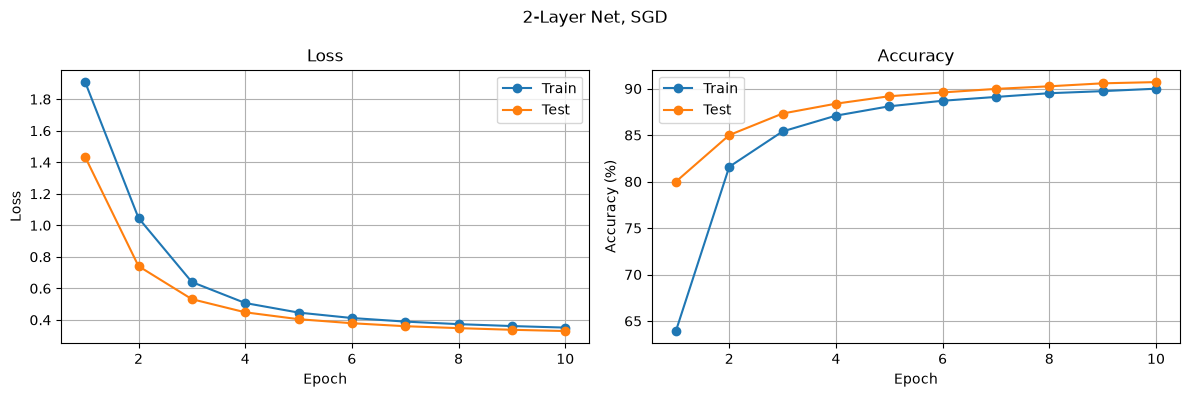

Accuracy: 90 %


In [34]:
# SGD
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr)

history_sgd = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_sgd, '2-Layer Net, SGD')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 1.2511  Train Acc: 76.28%  (12.0s)  |  Test Loss: 0.6189  Test Acc: 86.47%  (1.3s)
Epoch [2/10]  Train Loss: 0.5186  Train Acc: 86.94%  (11.8s)  |  Test Loss: 0.4221  Test Acc: 88.90%  (1.3s)
Epoch [3/10]  Train Loss: 0.4125  Train Acc: 88.71%  (11.4s)  |  Test Loss: 0.3676  Test Acc: 89.92%  (1.3s)
Epoch [4/10]  Train Loss: 0.3726  Train Acc: 89.49%  (11.3s)  |  Test Loss: 0.3404  Test Acc: 90.46%  (1.3s)
Epoch [5/10]  Train Loss: 0.3504  Train Acc: 90.02%  (11.2s)  |  Test Loss: 0.3243  Test Acc: 90.88%  (1.3s)
Epoch [6/10]  Train Loss: 0.3357  Train Acc: 90.37%  (11.4s)  |  Test Loss: 0.3142  Test Acc: 91.15%  (1.3s)
Epoch [7/10]  Train Loss: 0.3251  Train Acc: 90.65%  (11.3s)  |  Test Loss: 0.3055  Test Acc: 91.34%  (1.3s)
Epoch [8/10]  Train Loss: 0.3169  Train Acc: 90.91%  (11.5s)  |  Test Loss: 0.2987  Test Acc: 91.66%  (1.4s)
Epoch [9/10]  Train Loss: 0.3100  Train Acc: 91.11%  (12.0s)  |  Test Loss: 0.2924  Test Acc: 91.72%  (1.3s)
Epoch [10/10]  Trai

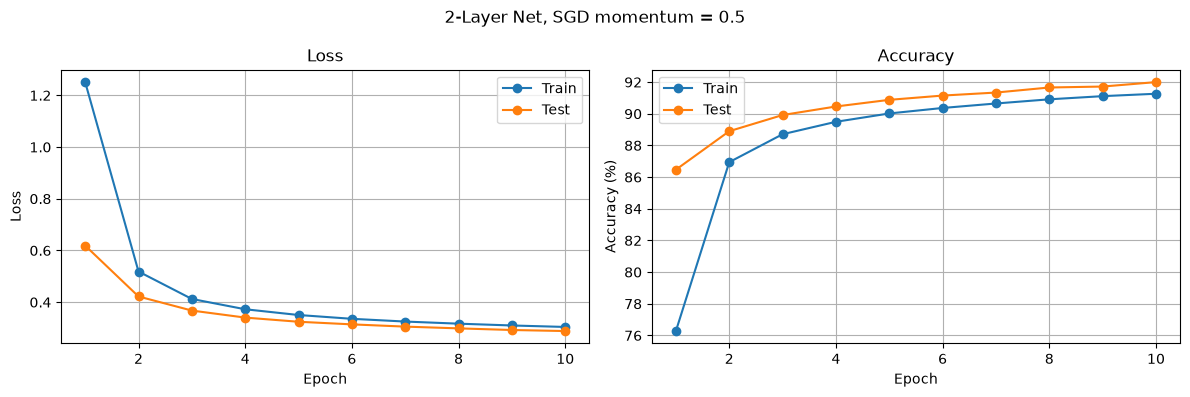

Accuracy: 92 %


In [35]:
# SGD 0.5
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.5)

history_sgd05 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_sgd05, '2-Layer Net, SGD momentum = 0.5')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.6088  Train Acc: 84.81%  (11.7s)  |  Test Loss: 0.3226  Test Acc: 90.81%  (1.2s)
Epoch [2/10]  Train Loss: 0.3174  Train Acc: 90.87%  (11.8s)  |  Test Loss: 0.2856  Test Acc: 91.90%  (1.3s)
Epoch [3/10]  Train Loss: 0.2876  Train Acc: 91.71%  (11.3s)  |  Test Loss: 0.2644  Test Acc: 92.61%  (1.3s)
Epoch [4/10]  Train Loss: 0.2681  Train Acc: 92.38%  (11.2s)  |  Test Loss: 0.2527  Test Acc: 92.99%  (1.4s)
Epoch [5/10]  Train Loss: 0.2527  Train Acc: 92.92%  (15.2s)  |  Test Loss: 0.2365  Test Acc: 93.51%  (1.4s)
Epoch [6/10]  Train Loss: 0.2394  Train Acc: 93.33%  (13.8s)  |  Test Loss: 0.2263  Test Acc: 93.62%  (1.9s)
Epoch [7/10]  Train Loss: 0.2259  Train Acc: 93.67%  (13.7s)  |  Test Loss: 0.2176  Test Acc: 94.13%  (1.4s)
Epoch [8/10]  Train Loss: 0.2136  Train Acc: 94.04%  (14.4s)  |  Test Loss: 0.2055  Test Acc: 94.19%  (1.8s)
Epoch [9/10]  Train Loss: 0.2021  Train Acc: 94.38%  (14.1s)  |  Test Loss: 0.1913  Test Acc: 94.58%  (1.3s)
Epoch [10/10]  Trai

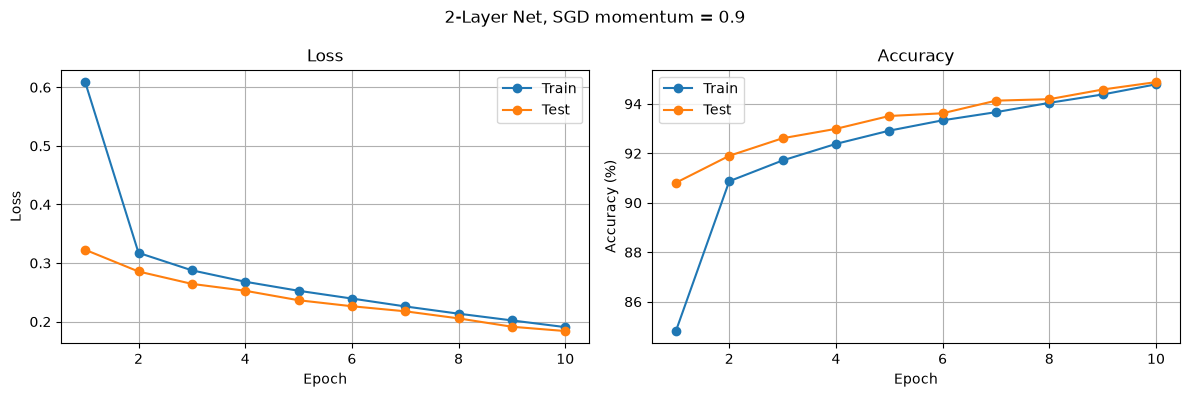

Accuracy: 94 %


In [36]:
# SGD 0.9
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)

history_sgd09 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_sgd09, '2-Layer Net, SGD momentum = 0.9')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

A 5.3.1

Differences:

SGD steps each weight in the direction that lowers the loss, with step size = learning rate. It has no memory of past steps, so it's slow and can zig-zag.

SGD with momentum adds memory of past steps, so it builds speed in consistent directions and smooths out zig-zags. Momentum 0.9 keeps more of that memory than 0.5, so it speeds up more.

Adam uses momentum plus a separate, automatically adjusted step size for each weight. That makes it fast and less sensitive to the learning rate.
Results (lr = 3e-4):

Adam: 98.29% test accuracy (best)
Adam: 98.29% test accuracy (best)
SGD: 90% test accuracy (slowest, still underfitting at epoch 10)
SGD momentum 0.5: 92% test accuracy
SGD momentum 0.9: 94% test accuracy
Overall: Adam > SGD 0.9 > SGD 0.5 > SGD. Momentum and adaptive step sizes make training faster at the same learning rate.



---

### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

Epoch [1/10]  Train Loss: 2.3018  Train Acc: 11.18%  (13.0s)  |  Test Loss: 2.3012  Test Acc: 11.35%  (1.3s)
Epoch [2/10]  Train Loss: 2.3013  Train Acc: 11.24%  (12.3s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.3s)
Epoch [3/10]  Train Loss: 2.3012  Train Acc: 11.24%  (12.5s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.3s)
Epoch [4/10]  Train Loss: 2.3012  Train Acc: 11.24%  (12.5s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.3s)
Epoch [5/10]  Train Loss: 2.3012  Train Acc: 11.24%  (13.0s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.2s)
Epoch [6/10]  Train Loss: 2.3012  Train Acc: 11.24%  (12.3s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.3s)
Epoch [7/10]  Train Loss: 2.3012  Train Acc: 11.24%  (12.6s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.3s)
Epoch [8/10]  Train Loss: 2.3012  Train Acc: 11.24%  (13.2s)  |  Test Loss: 2.3011  Test Acc: 11.35%  (1.4s)
Epoch [9/10]  Train Loss: 2.3012  Train Acc: 11.24%  (14.7s)  |  Test Loss: 2.3010  Test Acc: 11.35%  (1.6s)
Epoch [10/10]  Trai

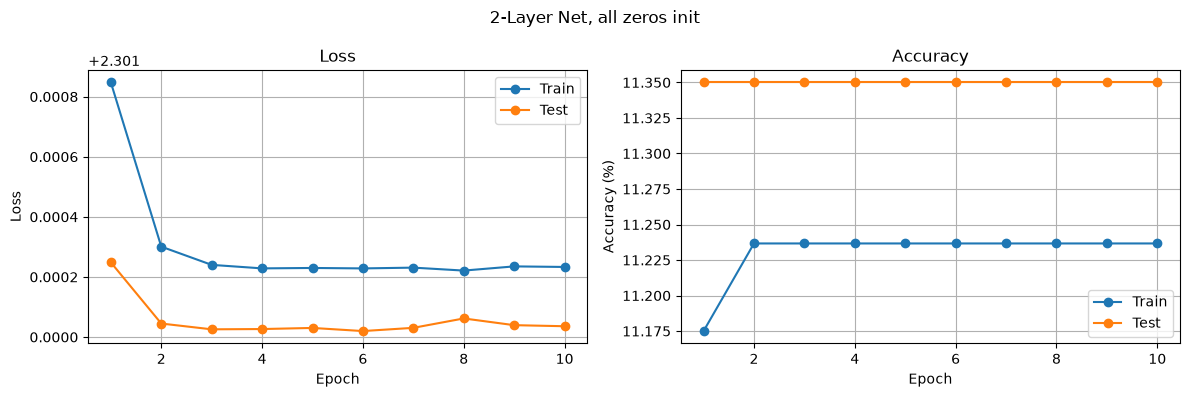

Accuracy: 11 %


In [37]:
# All zeros
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

def init_zeros(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.zeros_(m.weight)
        nn.init.zeros_(m.bias)

net = Net2(input_size, num_classes)
net.apply(init_zeros)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_zeros = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_zeros, '2-Layer Net, all zeros init')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.6141  Train Acc: 87.17%  (12.8s)  |  Test Loss: 0.4802  Test Acc: 88.72%  (1.3s)
Epoch [2/10]  Train Loss: 0.4088  Train Acc: 89.39%  (14.8s)  |  Test Loss: 0.3199  Test Acc: 91.56%  (1.4s)
Epoch [3/10]  Train Loss: 0.3484  Train Acc: 90.33%  (13.5s)  |  Test Loss: 0.3415  Test Acc: 90.39%  (1.3s)
Epoch [4/10]  Train Loss: 0.3380  Train Acc: 90.77%  (13.6s)  |  Test Loss: 0.3113  Test Acc: 91.47%  (1.4s)
Epoch [5/10]  Train Loss: 0.3278  Train Acc: 91.07%  (15.4s)  |  Test Loss: 0.3140  Test Acc: 91.52%  (1.4s)
Epoch [6/10]  Train Loss: 0.3158  Train Acc: 91.28%  (14.1s)  |  Test Loss: 0.2960  Test Acc: 91.90%  (1.6s)
Epoch [7/10]  Train Loss: 0.3044  Train Acc: 91.62%  (14.4s)  |  Test Loss: 0.2991  Test Acc: 91.98%  (1.8s)
Epoch [8/10]  Train Loss: 0.2953  Train Acc: 91.87%  (15.1s)  |  Test Loss: 0.2856  Test Acc: 92.23%  (1.9s)
Epoch [9/10]  Train Loss: 0.2856  Train Acc: 92.04%  (13.8s)  |  Test Loss: 0.2792  Test Acc: 92.11%  (2.0s)
Epoch [10/10]  Trai

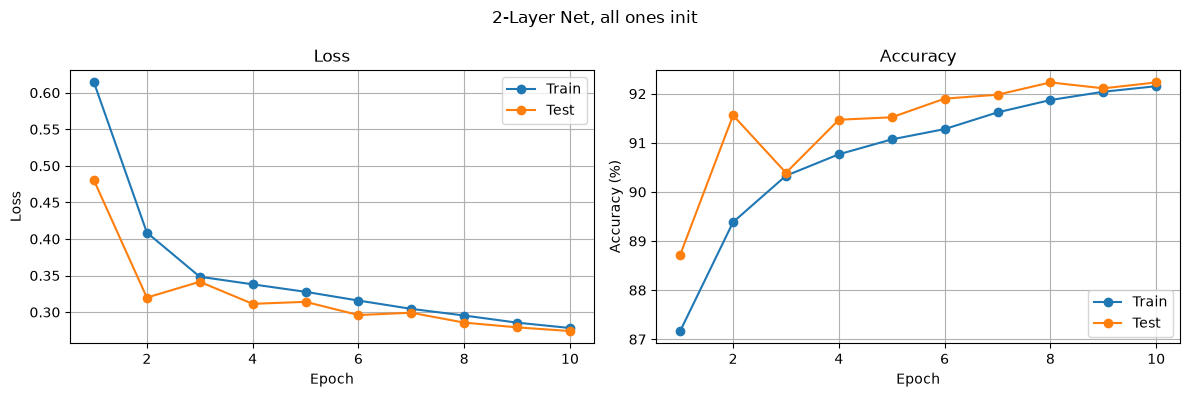

Accuracy: 92 %


In [40]:
# All ones
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

def init_ones(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.ones_(m.weight)
        nn.init.zeros_(m.bias)

net = Net2(input_size, num_classes)
net.apply(init_ones)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_ones = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_ones, '2-Layer Net, all ones init')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.3801  Train Acc: 89.59%  (13.0s)  |  Test Loss: 0.2216  Test Acc: 93.55%  (1.4s)
Epoch [2/10]  Train Loss: 0.1868  Train Acc: 94.71%  (12.0s)  |  Test Loss: 0.1414  Test Acc: 96.31%  (1.4s)
Epoch [3/10]  Train Loss: 0.1278  Train Acc: 96.53%  (11.6s)  |  Test Loss: 0.1076  Test Acc: 97.13%  (1.2s)
Epoch [4/10]  Train Loss: 0.0983  Train Acc: 97.30%  (11.5s)  |  Test Loss: 0.0849  Test Acc: 97.62%  (1.2s)
Epoch [5/10]  Train Loss: 0.0804  Train Acc: 97.82%  (12.0s)  |  Test Loss: 0.0793  Test Acc: 97.76%  (1.3s)
Epoch [6/10]  Train Loss: 0.0684  Train Acc: 98.11%  (11.6s)  |  Test Loss: 0.0701  Test Acc: 97.96%  (1.2s)
Epoch [7/10]  Train Loss: 0.0596  Train Acc: 98.30%  (11.6s)  |  Test Loss: 0.0660  Test Acc: 97.96%  (1.2s)
Epoch [8/10]  Train Loss: 0.0529  Train Acc: 98.52%  (12.1s)  |  Test Loss: 0.0646  Test Acc: 98.00%  (1.2s)
Epoch [9/10]  Train Loss: 0.0480  Train Acc: 98.65%  (11.6s)  |  Test Loss: 0.0614  Test Acc: 98.07%  (1.2s)
Epoch [10/10]  Trai

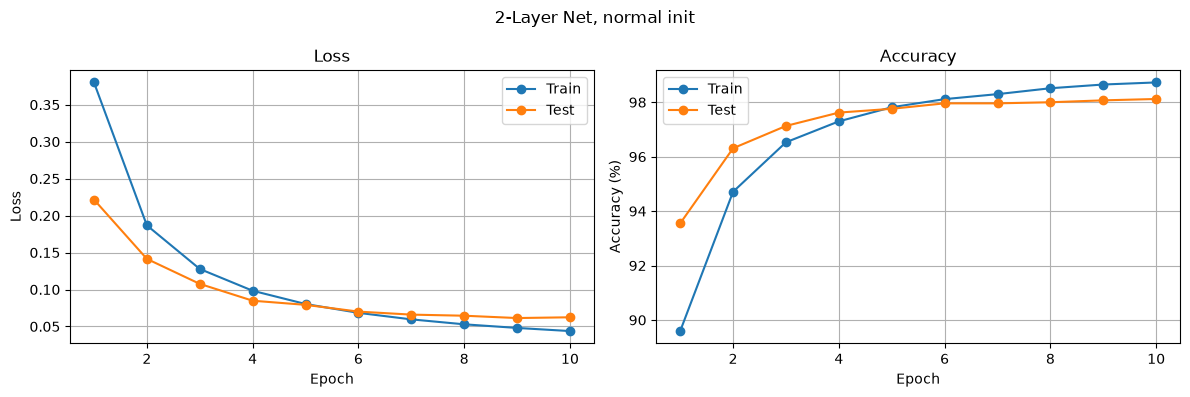

Accuracy: 98 %


In [38]:
# Random
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

def init_normal(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.normal_(m.weight, mean=0.0, std=0.01)
        nn.init.zeros_(m.bias)

net = Net2(input_size, num_classes)
net.apply(init_normal)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_normal = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_normal, '2-Layer Net, normal init')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

All zeros (11%): The model didn't learn. When every weight is 0, the gradients are also 0, so the weights never update. The model just guesses (about 10% for 10 digits).

All ones (92%): The model learned, but worse than with random weights. All the filters start the same, so they get the same updates and stay the same. The network acts like it has only one filter. We expected this to do badly, but it still got 92% because MNIST is an easy dataset and a very simple model can still get most digits right.

Random (98%): Best result. Each weight starts different, so each filter learns something different

Recommendation: Initialize weights with small random values. Random so that neurons don't all learn the same thing, and small so that values don't blow up at the start. Don't set all weights to the same number.

---

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10]  Train Loss: 0.3695  Train Acc: 89.25%  (13.3s)  |  Test Loss: 0.2837  Test Acc: 91.77%  (1.4s)
Epoch [2/10]  Train Loss: 0.2768  Train Acc: 92.22%  (13.1s)  |  Test Loss: 0.2512  Test Acc: 92.99%  (1.4s)
Epoch [3/10]  Train Loss: 0.2451  Train Acc: 92.97%  (12.5s)  |  Test Loss: 0.2252  Test Acc: 93.68%  (1.4s)
Epoch [4/10]  Train Loss: 0.2134  Train Acc: 93.93%  (12.6s)  |  Test Loss: 0.2098  Test Acc: 94.19%  (1.5s)
Epoch [5/10]  Train Loss: 0.1827  Train Acc: 94.88%  (12.9s)  |  Test Loss: 0.1813  Test Acc: 94.68%  (1.4s)
Epoch [6/10]  Train Loss: 0.1530  Train Acc: 95.63%  (12.7s)  |  Test Loss: 0.1705  Test Acc: 95.27%  (1.4s)
Epoch [7/10]  Train Loss: 0.1263  Train Acc: 96.47%  (13.2s)  |  Test Loss: 0.1310  Test Acc: 96.42%  (1.5s)
Epoch [8/10]  Train Loss: 0.1054  Train Acc: 96.96%  (13.5s)  |  Test Loss: 0.1171  Test Acc: 96.73%  (1.5s)
Epoch [9/10]  Train Loss: 0.0910  Train Acc: 97.34%  (12.9s)  |  Test Loss: 0.1075  Test Acc: 96.72%  (1.4s)
Epoch [10/10]  Trai

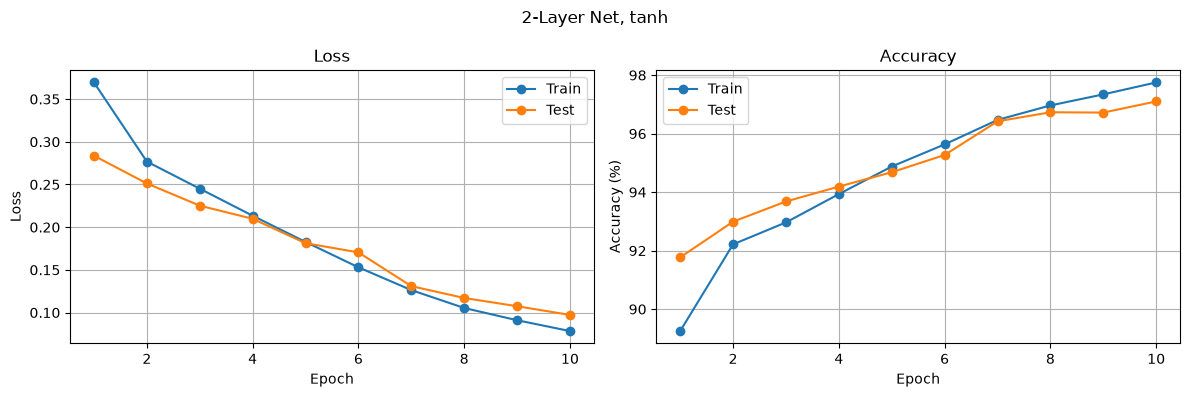

Accuracy: 97 %


In [41]:
# 2-Layer CNN with tanh instead of ReLU
class Net2Tanh(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net2Tanh, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=20, kernel_size=3, stride=1)  # 1x28x28 -> 20x26x26
        self.tanh = nn.Tanh()
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes)                                  # 13520 -> 10

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.conv1(x)
        out = self.tanh(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        return out


input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10

net = Net2Tanh(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_tanh = train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(history_tanh, '2-Layer Net, tanh')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

Changing ReLU to tanh made the model slightly worse: 97% test accuracy compared with 98% for ReLU. With tanh, the curve flattens out for large inputs, so the gradient becomes very small and the weights update more slowly. ReLU has a constant gradient of 1 for positive inputs, so it keeps learning at full speed.





---

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch [1/10]  Train Loss: 0.2441  Train Acc: 92.99%  (22.6s)  |  Test Loss: 0.1141  Test Acc: 96.74%  (1.4s)
Epoch [2/10]  Train Loss: 0.0903  Train Acc: 97.41%  (23.9s)  |  Test Loss: 0.0721  Test Acc: 97.75%  (1.3s)
Epoch [3/10]  Train Loss: 0.0602  Train Acc: 98.22%  (28.1s)  |  Test Loss: 0.0666  Test Acc: 97.98%  (1.7s)
Epoch [4/10]  Train Loss: 0.0463  Train Acc: 98.63%  (25.1s)  |  Test Loss: 0.0622  Test Acc: 98.07%  (1.5s)
Epoch [5/10]  Train Loss: 0.0373  Train Acc: 98.90%  (24.6s)  |  Test Loss: 0.0587  Test Acc: 98.21%  (1.4s)
Epoch [6/10]  Train Loss: 0.0306  Train Acc: 99.07%  (26.6s)  |  Test Loss: 0.0633  Test Acc: 98.08%  (1.4s)
Epoch [7/10]  Train Loss: 0.0247  Train Acc: 99.29%  (22.0s)  |  Test Loss: 0.0659  Test Acc: 98.17%  (1.3s)
Epoch [8/10]  Train Loss: 0.0207  Train Acc: 99.39%  (21.8s)  |  Test Loss: 0.0672  Test Acc: 98.08%  (1.4s)
Epoch [9/10]  Train Loss: 0.0168  Train Acc: 99.53%  (21.3s)  |  Test Loss: 0.0670  Test Acc: 98.16%  (1.3s)
Epoch [10/10]  Trai

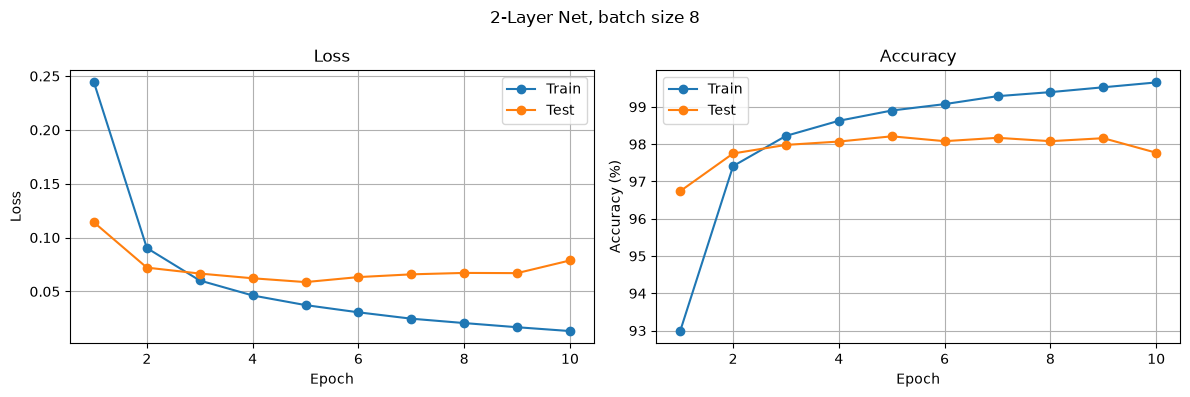

Accuracy: 97 %


In [42]:
# Batch size 8
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_8 = 8

train_loader_8 = torch.utils.data.DataLoader(dataset = train_data,
                                             batch_size = batch_size_8,
                                             shuffle = True)

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_bs8 = train(net, loss_function, optimizer, train_loader_8, test_loader, batch_size_8, num_epochs, device)
plot_learning_curve(history_bs8, '2-Layer Net, batch size 8')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.3926  Train Acc: 89.12%  (12.4s)  |  Test Loss: 0.2367  Test Acc: 93.47%  (1.4s)
Epoch [2/10]  Train Loss: 0.2072  Train Acc: 94.02%  (10.7s)  |  Test Loss: 0.1651  Test Acc: 95.27%  (1.3s)
Epoch [3/10]  Train Loss: 0.1456  Train Acc: 95.84%  (11.0s)  |  Test Loss: 0.1350  Test Acc: 96.00%  (1.5s)
Epoch [4/10]  Train Loss: 0.1088  Train Acc: 96.98%  (11.3s)  |  Test Loss: 0.1068  Test Acc: 97.00%  (1.3s)
Epoch [5/10]  Train Loss: 0.0881  Train Acc: 97.61%  (10.7s)  |  Test Loss: 0.0908  Test Acc: 97.24%  (1.3s)
Epoch [6/10]  Train Loss: 0.0734  Train Acc: 97.94%  (10.8s)  |  Test Loss: 0.0738  Test Acc: 97.77%  (1.3s)
Epoch [7/10]  Train Loss: 0.0636  Train Acc: 98.25%  (11.1s)  |  Test Loss: 0.0723  Test Acc: 97.76%  (1.4s)
Epoch [8/10]  Train Loss: 0.0551  Train Acc: 98.43%  (10.8s)  |  Test Loss: 0.0666  Test Acc: 98.08%  (1.3s)
Epoch [9/10]  Train Loss: 0.0489  Train Acc: 98.62%  (10.9s)  |  Test Loss: 0.0646  Test Acc: 98.07%  (1.3s)
Epoch [10/10]  Trai

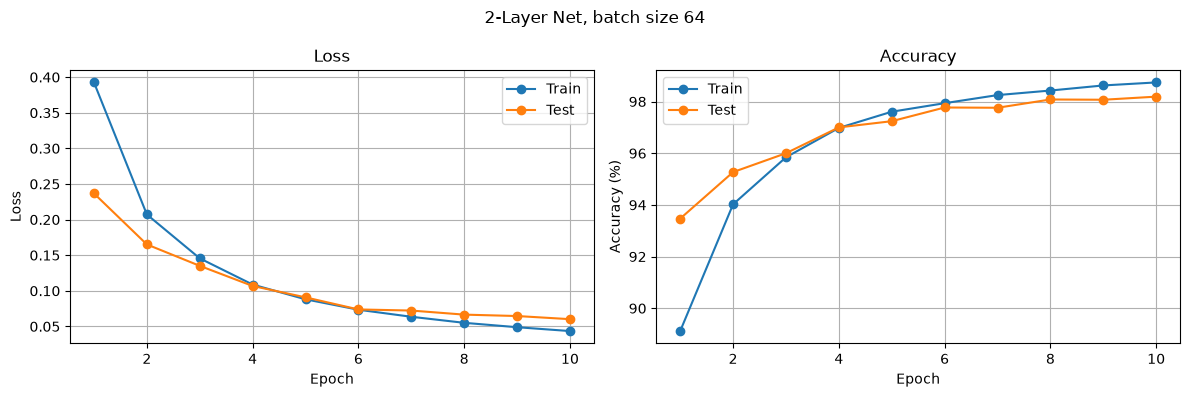

Accuracy: 98 %


In [43]:
# Batch size 64
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_64 = 64

train_loader_64 = torch.utils.data.DataLoader(dataset = train_data,
                                              batch_size = batch_size_64,
                                              shuffle = True)

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_bs64 = train(net, loss_function, optimizer, train_loader_64, test_loader, batch_size_64, num_epochs, device)
plot_learning_curve(history_bs64, '2-Layer Net, batch size 64')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.4544  Train Acc: 88.22%  (10.7s)  |  Test Loss: 0.2104  Test Acc: 94.14%  (1.3s)
Epoch [2/10]  Train Loss: 0.1885  Train Acc: 94.60%  (10.4s)  |  Test Loss: 0.1621  Test Acc: 95.49%  (1.3s)
Epoch [3/10]  Train Loss: 0.1444  Train Acc: 95.89%  (10.8s)  |  Test Loss: 0.1288  Test Acc: 96.45%  (1.4s)
Epoch [4/10]  Train Loss: 0.1198  Train Acc: 96.66%  (10.9s)  |  Test Loss: 0.1179  Test Acc: 96.60%  (1.3s)
Epoch [5/10]  Train Loss: 0.1030  Train Acc: 97.13%  (10.2s)  |  Test Loss: 0.1131  Test Acc: 96.65%  (1.2s)
Epoch [6/10]  Train Loss: 0.0905  Train Acc: 97.52%  (10.4s)  |  Test Loss: 0.0947  Test Acc: 97.11%  (1.4s)
Epoch [7/10]  Train Loss: 0.0801  Train Acc: 97.77%  (10.3s)  |  Test Loss: 0.0883  Test Acc: 97.54%  (1.3s)
Epoch [8/10]  Train Loss: 0.0719  Train Acc: 97.97%  (10.5s)  |  Test Loss: 0.0784  Test Acc: 97.60%  (1.3s)
Epoch [9/10]  Train Loss: 0.0654  Train Acc: 98.17%  (10.5s)  |  Test Loss: 0.0779  Test Acc: 97.79%  (1.4s)
Epoch [10/10]  Trai

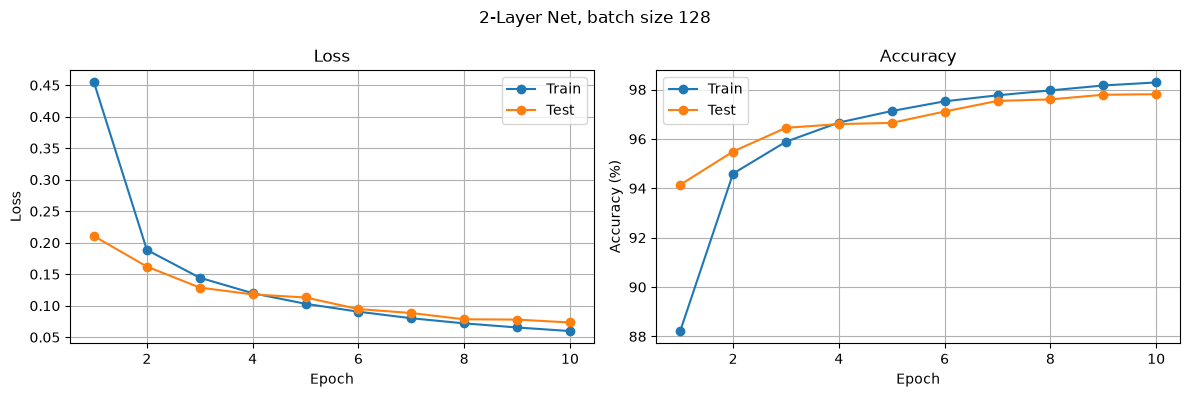

Accuracy: 97 %


In [44]:
# Batch size 128
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_128 = 128

train_loader_128 = torch.utils.data.DataLoader(dataset = train_data,
                                               batch_size = batch_size_128,
                                               shuffle = True)

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_bs128 = train(net, loss_function, optimizer, train_loader_128, test_loader, batch_size_128, num_epochs, device)
plot_learning_curve(history_bs128, '2-Layer Net, batch size 128')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

Batch size is how many images the model sees before each weight update.

Batch 8 (97%): Lots of small, noisy updates. Slowest to train.

Batch 64 (98%): Best balance of stable updates and enough of them, so it got the best accuracy.

Batch 128 (97%): Smooth updates and fastest per epoch, but fewer updates, so it learned a bit slower.

Small batches are noisy and slow, and large batches are smooth but update less often. The middle worked best

---

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [51]:
# Define 5-Layer Network
class Net5(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net5, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5, stride=1, padding=2)   # 1x28x28 -> 32x28x28
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)                                          # 32x28x28 -> 32x14x14
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2)  # 32x14x14 -> 64x14x14
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)                                                   # 12544 -> 1024
        self.fc2 = nn.Linear(1024, num_classes)                                                    # 1024 -> 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)        # train/test_accuracy pass flat (batch, 784) -> back to images
        out = self.relu(self.conv1(x))
        out = self.pool(out)
        out = self.relu(self.conv2(out))
        out = out.view(out.size(0), -1)  # flatten (batch, 64, 14, 14) -> (batch, 12544)
        out = self.relu(self.fc1(out))
        out = self.fc2(out)
        return out


#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [57]:
# Define FCN
class FCN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(FCN, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)   # 784 -> 256
        self.fc2 = nn.Linear(256, 256)          # 256 -> 256
        self.fc3 = nn.Linear(256, num_classes)  # 256 -> 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)  # make sure input is flat (batch, 784)
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        return out


#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


Epoch [1/10]  Train Loss: 0.3692  Train Acc: 89.89%  (12.4s)  |  Test Loss: 0.2236  Test Acc: 93.65%  (1.3s)
Epoch [2/10]  Train Loss: 0.1889  Train Acc: 94.64%  (11.2s)  |  Test Loss: 0.1490  Test Acc: 96.07%  (1.3s)
Epoch [3/10]  Train Loss: 0.1296  Train Acc: 96.46%  (11.1s)  |  Test Loss: 0.1092  Test Acc: 96.94%  (1.3s)
Epoch [4/10]  Train Loss: 0.0972  Train Acc: 97.37%  (11.5s)  |  Test Loss: 0.0933  Test Acc: 97.35%  (1.3s)
Epoch [5/10]  Train Loss: 0.0783  Train Acc: 97.80%  (11.1s)  |  Test Loss: 0.0755  Test Acc: 97.86%  (1.3s)
Epoch [6/10]  Train Loss: 0.0645  Train Acc: 98.22%  (11.1s)  |  Test Loss: 0.0744  Test Acc: 97.85%  (1.4s)
Epoch [7/10]  Train Loss: 0.0561  Train Acc: 98.43%  (11.4s)  |  Test Loss: 0.0667  Test Acc: 97.81%  (1.4s)
Epoch [8/10]  Train Loss: 0.0485  Train Acc: 98.70%  (11.0s)  |  Test Loss: 0.0670  Test Acc: 97.87%  (1.3s)
Epoch [9/10]  Train Loss: 0.0433  Train Acc: 98.81%  (11.1s)  |  Test Loss: 0.0607  Test Acc: 98.07%  (1.4s)
Epoch [10/10]  Trai

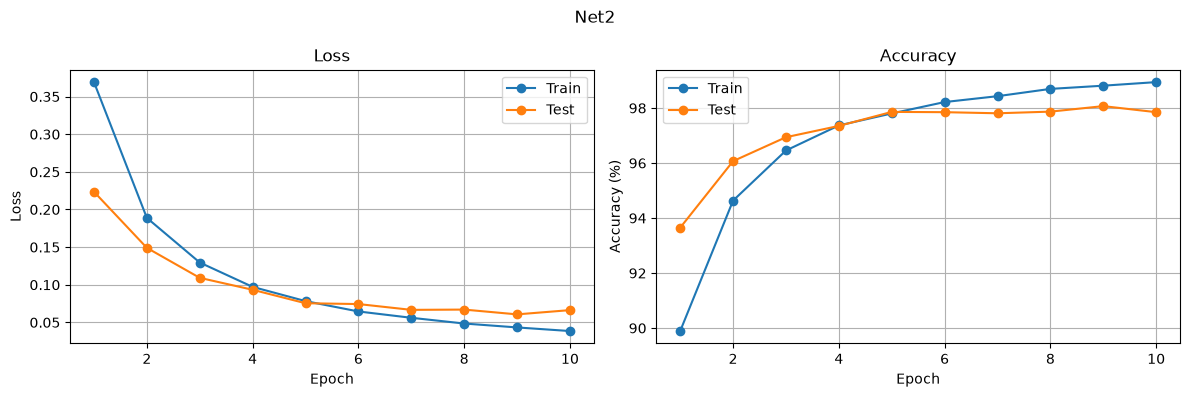

Accuracy: 97 %


In [58]:
# Net2
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_64 = 64

train_loader_64 = torch.utils.data.DataLoader(dataset = train_data,
                                              batch_size = batch_size_64,
                                              shuffle = True)

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_net2 = train(net, loss_function, optimizer, train_loader_64, test_loader, batch_size_64, num_epochs, device)
plot_learning_curve(history_net2, 'Net2')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.1587  Train Acc: 95.29%  (125.0s)  |  Test Loss: 0.0457  Test Acc: 98.38%  (4.7s)
Epoch [2/10]  Train Loss: 0.0451  Train Acc: 98.60%  (122.1s)  |  Test Loss: 0.0349  Test Acc: 98.86%  (4.4s)
Epoch [3/10]  Train Loss: 0.0310  Train Acc: 99.00%  (121.3s)  |  Test Loss: 0.0301  Test Acc: 99.02%  (4.7s)
Epoch [4/10]  Train Loss: 0.0209  Train Acc: 99.32%  (118.3s)  |  Test Loss: 0.0253  Test Acc: 99.23%  (4.2s)
Epoch [5/10]  Train Loss: 0.0162  Train Acc: 99.47%  (120.4s)  |  Test Loss: 0.0274  Test Acc: 99.12%  (6.0s)
Epoch [6/10]  Train Loss: 0.0116  Train Acc: 99.66%  (133.7s)  |  Test Loss: 0.0271  Test Acc: 99.12%  (4.9s)
Epoch [7/10]  Train Loss: 0.0096  Train Acc: 99.67%  (128.5s)  |  Test Loss: 0.0369  Test Acc: 99.00%  (4.3s)
Epoch [8/10]  Train Loss: 0.0082  Train Acc: 99.74%  (117.1s)  |  Test Loss: 0.0276  Test Acc: 99.16%  (4.2s)
Epoch [9/10]  Train Loss: 0.0063  Train Acc: 99.77%  (118.9s)  |  Test Loss: 0.0319  Test Acc: 99.04%  (5.7s)
Epoch [10/

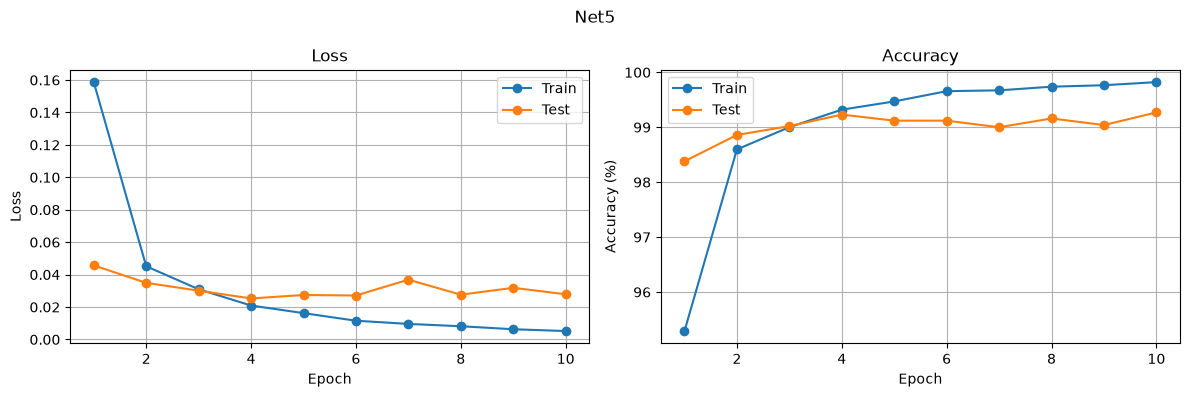

Accuracy: 99 %


In [59]:
# Net5
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_64 = 64

train_loader_64 = torch.utils.data.DataLoader(dataset = train_data,
                                              batch_size = batch_size_64,
                                              shuffle = True)

net = Net5(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_net5 = train(net, loss_function, optimizer, train_loader_64, test_loader, batch_size_64, num_epochs, device)
plot_learning_curve(history_net5, 'Net5')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


Epoch [1/10]  Train Loss: 0.4144  Train Acc: 88.84%  (9.2s)  |  Test Loss: 0.2216  Test Acc: 93.42%  (1.2s)
Epoch [2/10]  Train Loss: 0.1760  Train Acc: 94.92%  (8.5s)  |  Test Loss: 0.1444  Test Acc: 95.65%  (1.2s)
Epoch [3/10]  Train Loss: 0.1232  Train Acc: 96.36%  (8.5s)  |  Test Loss: 0.1139  Test Acc: 96.60%  (1.2s)
Epoch [4/10]  Train Loss: 0.0911  Train Acc: 97.31%  (8.9s)  |  Test Loss: 0.0962  Test Acc: 97.09%  (1.3s)
Epoch [5/10]  Train Loss: 0.0713  Train Acc: 97.89%  (8.6s)  |  Test Loss: 0.0831  Test Acc: 97.48%  (1.2s)
Epoch [6/10]  Train Loss: 0.0564  Train Acc: 98.31%  (8.9s)  |  Test Loss: 0.0783  Test Acc: 97.71%  (1.3s)
Epoch [7/10]  Train Loss: 0.0465  Train Acc: 98.63%  (8.4s)  |  Test Loss: 0.0866  Test Acc: 97.20%  (1.1s)
Epoch [8/10]  Train Loss: 0.0368  Train Acc: 98.87%  (8.9s)  |  Test Loss: 0.0693  Test Acc: 97.87%  (1.2s)
Epoch [9/10]  Train Loss: 0.0298  Train Acc: 99.08%  (8.4s)  |  Test Loss: 0.0736  Test Acc: 97.91%  (1.1s)
Epoch [10/10]  Train Loss: 0

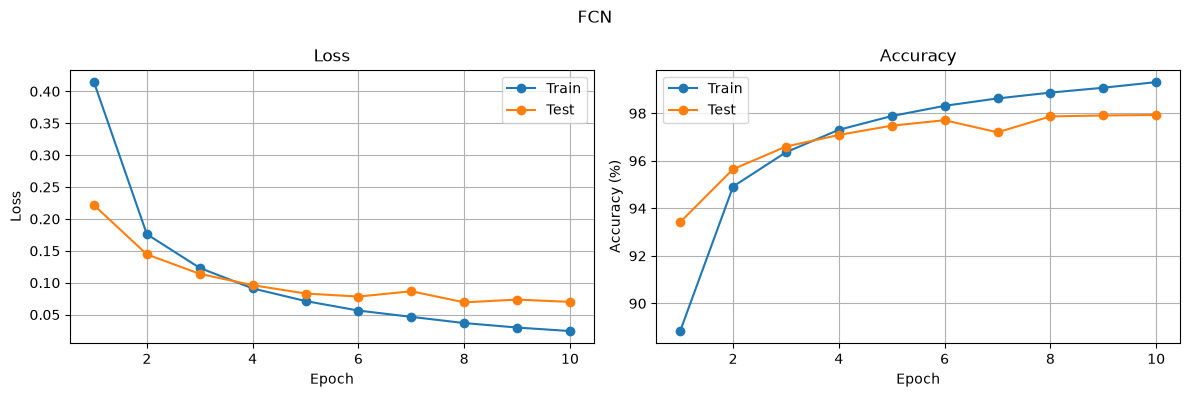

Accuracy: 97 %


In [60]:
# FCN
input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_64 = 64

train_loader_64 = torch.utils.data.DataLoader(dataset = train_data,
                                              batch_size = batch_size_64,
                                              shuffle = True)

net = FCN(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_fcn = train(net, loss_function, optimizer, train_loader_64, test_loader, batch_size_64, num_epochs, device)
plot_learning_curve(history_fcn, 'FCN')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

Net5 (99%) is the best. It has the most layers, so it can learn more complex patterns.

Net2 (97%) has only one conv layer, so it learns simpler patterns.

FCN (97%) flattens the image, so it loses which pixels are next to each other and can't learn shapes well.

This matches what we expected: the biggest CNN did best.

#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

Net5 converges fastest: its test loss leveled off by epoch 4, while Net2 and FCN took about 8–9 epochs. This is because Net5 has more layers and filters, so it learns useful patterns faster. However, each Net5 epoch took about 10x longer to run because it's a much bigger model. To make a model converge faster, you can raise the learning rate (not too high), use Adam or SGD with momentum, or use a smaller batch size.

#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

The pooling layer shrinks the image by keeping only the strongest value in each small area. In Net5, max pooling with a 2×2 window takes the 28×28 feature maps down to 14×14. This cuts the amount of computation and the number of weights the next layers need, which speeds up training. It also makes the model less sensitive to small shifts in where a feature appears, so a digit that moves slightly is still recognized.

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

Yes. Accuracy only checks whether the top guess is right, but loss also measures how confident the model is. A model can be very confident on most images, which gives a low loss, but get a few more of them wrong, which gives lower accuracy. Our results show this: Net2 had a lower final test loss than FCN (0.066 vs 0.070) but slightly worse test accuracy (97.85% vs 97.93%).

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

An FCN flattens the image into a long list of pixels, so it loses which pixels are next to each other. A CNN keeps the image's shape and uses small filters that slide over it to find patterns like edges and curves anywhere in the image. Because of this, CNNs understand images better and usually get higher accuracy, like Net5 at 99%.






---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



Epoch [1/10]  Train Loss: 0.0884  Train Acc: 97.36%  (130.3s)  |  Test Loss: 0.0322  Test Acc: 98.96%  (4.5s)
Epoch [2/10]  Train Loss: 0.0313  Train Acc: 99.02%  (124.4s)  |  Test Loss: 0.0301  Test Acc: 98.94%  (4.4s)
Epoch [3/10]  Train Loss: 0.0218  Train Acc: 99.32%  (125.4s)  |  Test Loss: 0.0301  Test Acc: 99.05%  (4.4s)
Epoch [4/10]  Train Loss: 0.0156  Train Acc: 99.52%  (122.7s)  |  Test Loss: 0.0297  Test Acc: 99.06%  (4.3s)
Epoch [5/10]  Train Loss: 0.0116  Train Acc: 99.63%  (123.2s)  |  Test Loss: 0.0297  Test Acc: 99.10%  (4.3s)
Epoch [6/10]  Train Loss: 0.0097  Train Acc: 99.68%  (122.2s)  |  Test Loss: 0.0332  Test Acc: 99.01%  (4.3s)
Epoch [7/10]  Train Loss: 0.0077  Train Acc: 99.76%  (129.3s)  |  Test Loss: 0.0285  Test Acc: 99.10%  (4.3s)
Epoch [8/10]  Train Loss: 0.0066  Train Acc: 99.78%  (129.3s)  |  Test Loss: 0.0276  Test Acc: 99.14%  (4.3s)
Epoch [9/10]  Train Loss: 0.0057  Train Acc: 99.84%  (121.7s)  |  Test Loss: 0.0263  Test Acc: 99.20%  (4.3s)
Epoch [10/

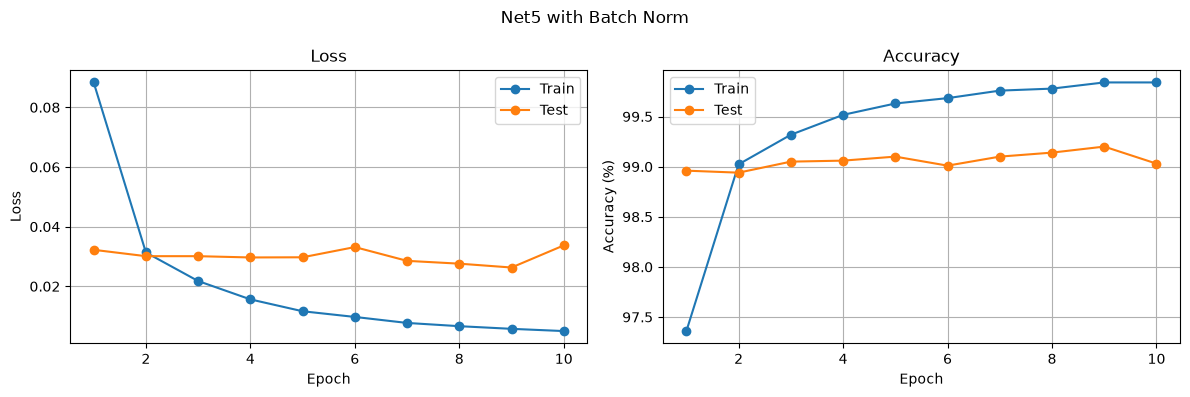

Accuracy: 99 %


In [61]:
# Net5 with Batch Normalization
class Net5BN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net5BN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5, stride=1, padding=2)   # 1x28x28 -> 32x28x28
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)                                          # 32x28x28 -> 32x14x14
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2)  # 32x14x14 -> 64x14x14
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)                                                   # 12544 -> 1024
        self.bn3 = nn.BatchNorm1d(1024)
        self.fc2 = nn.Linear(1024, num_classes)                                                    # 1024 -> 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.pool(out)
        out = self.relu(self.bn2(self.conv2(out)))
        out = out.view(out.size(0), -1)
        out = self.relu(self.bn3(self.fc1(out)))
        out = self.fc2(out)
        return out


input_size = 784
num_classes = 10
lr = 3e-4
num_epochs = 10
batch_size_64 = 64

train_loader_64 = torch.utils.data.DataLoader(dataset = train_data,
                                              batch_size = batch_size_64,
                                              shuffle = True)

net = Net5BN(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

history_net5bn = train(net, loss_function, optimizer, train_loader_64, test_loader, batch_size_64, num_epochs, device)
plot_learning_curve(history_net5bn, 'Net5 with Batch Norm')
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)


#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

Batch normalization rescales each layer's outputs so they keep a steady average and spread on every batch. This stops the values from drifting as the weights change, which makes training more stable and faster. In our results, Net5 with batch norm was already at 98.96% test accuracy after epoch 1, compared with 98.38% without it, and its test loss leveled off by epoch 2 instead of epoch 4. Both models still ended at 99%, because Net5 was already training very well on MNIST.



---
---

# End of Phase 1 😊🥳